# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('../data/global_energy_mix.csv')

source_category = {
    'Coal': 'Fossil',
    'Oil': 'Fossil',
    'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon',
    'Hydro': 'Low-carbon',
    'Wind': 'Renewable',
    'Solar': 'Renewable',
    'Other Renewables': 'Renewable'
}

df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))

Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


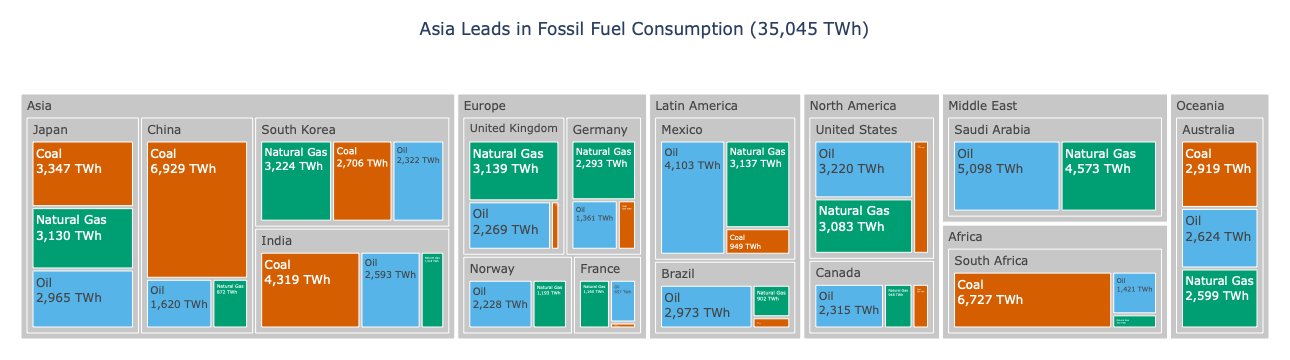

Total fossil fuel records: 43
Leading region: Asia
Fossil fuel consumption: 35045.1 TWh


In [5]:

# Task 1 — Fossil Fuel Treemap (Version 2)

# Filter fossil fuel sources
df_fossil = df[df['Source_Type'] == 'Fossil'].copy()

# Calculate total fossil fuel consumption by region
region_totals = (
    df_fossil.groupby('Region')['TWh']
    .sum()
    .sort_values(ascending=False)
)

# Identify the leading region
leading_region = region_totals.index[0]
leading_value = region_totals.iloc[0]

# New CVD-safe colour palette
fossil_colors_v2 = {
    'Coal': '#D55E00',
    'Oil': '#56B4E9',
    'Natural Gas': '#009E73'
}

# Create treemap
fig1 = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colors_v2,
    title=(
        f'{leading_region} Leads in Fossil Fuel Consumption '
        f'({leading_value:,.0f} TWh)'
    )
)

# Grey parent nodes and colour individual energy sources
node_colors = [
    fossil_colors_v2.get(node.split('/')[-1], '#C7C7C7')
    if node.count('/') == 2 else '#C7C7C7'
    for node in fig1.data[0].ids
]

fig1.update_traces(
    marker=dict(colors=node_colors),
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='%{label}<br>%{value:,.0f} TWh<extra></extra>'
)

fig1.update_layout(
    template='plotly_white',
    title_x=0.5,
    margin=dict(t=70, l=15, r=15, b=15)
)

fig1.show()

print("Total fossil fuel records:", len(df_fossil))
print("Leading region:", leading_region)
print("Fossil fuel consumption:", round(leading_value, 2), "TWh")


## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

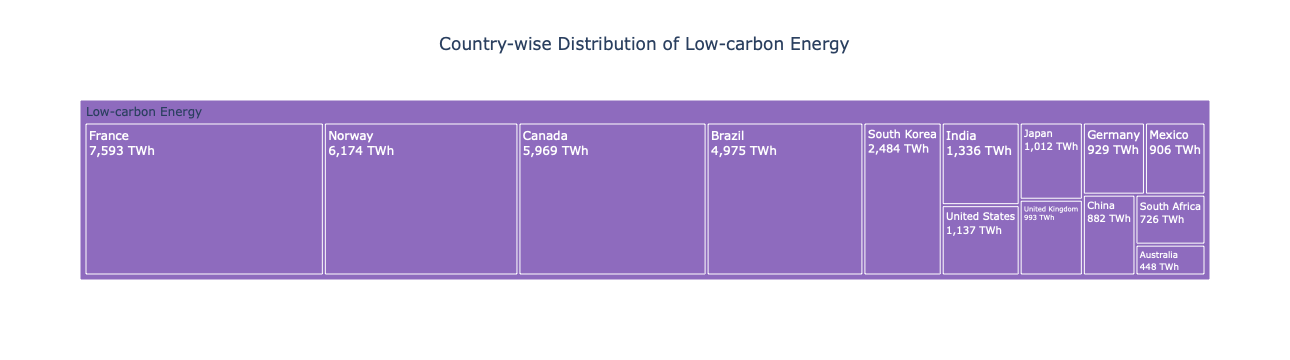

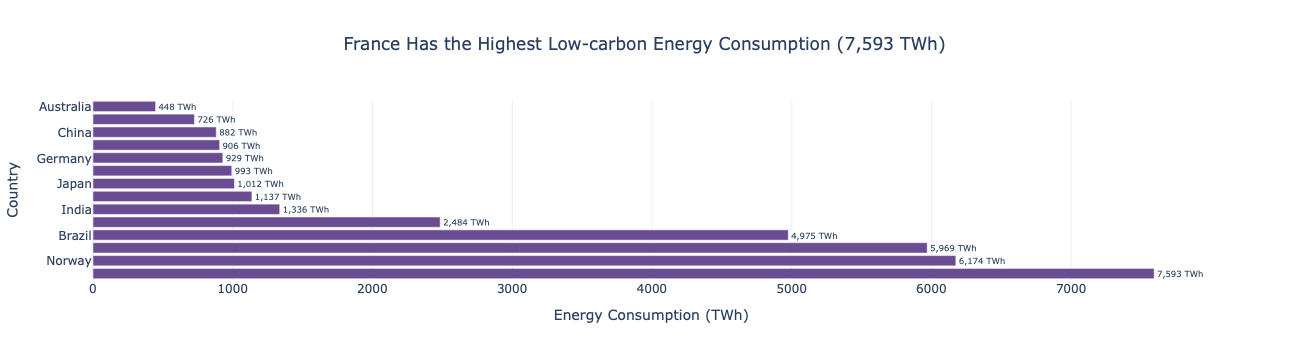

Leading country: France
Low-carbon energy: 7593.0 TWh


In [6]:

# Task 2 — Low-carbon Energy (Version 2)

# Filter Nuclear and Hydro
df_low = df[df['Source_Type'] == 'Low-carbon'].copy()

# Calculate total low-carbon TWh per country
country_totals = (
    df_low.groupby('Country', as_index=False)['TWh']
    .sum()
    .sort_values('TWh', ascending=False)
)

# Add dummy root for treemap
country_totals['All'] = 'Low-carbon Energy'

# Identify the country with the highest value
leading_country = country_totals.iloc[0]['Country']
leading_twh = country_totals.iloc[0]['TWh']


# Chart 1 — Treemap
fig2 = px.treemap(
    country_totals,
    path=['All', 'Country'],
    values='TWh',
    color='All',
    color_discrete_map={
        'Low-carbon Energy': '#8E6BBE'
    },
    title='Country-wise Distribution of Low-carbon Energy'
)

fig2.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='%{label}<br>%{value:,.0f} TWh<extra></extra>'
)

fig2.update_layout(
    template='plotly_white',
    title_x=0.5
)

fig2.show()


# Chart 2 — Horizontal Bar Chart
fig3 = px.bar(
    country_totals.sort_values('TWh', ascending=True),
    x='TWh',
    y='Country',
    orientation='h',
    text='TWh',
    color_discrete_sequence=['#6A4C93'],
    title=(
        f'{leading_country} Has the Highest Low-carbon Energy '
        f'Consumption ({leading_twh:,.0f} TWh)'
    ),
    labels={
        'TWh': 'Low-carbon Energy (TWh)',
        'Country': 'Country'
    }
)

fig3.update_traces(
    texttemplate='%{x:,.0f} TWh',
    textposition='outside'
)

fig3.update_layout(
    template='plotly_white',
    title_x=0.5,
    xaxis_title='Energy Consumption (TWh)',
    yaxis_title='Country',
    yaxis=dict(autorange='reversed')
)

fig3.show()

print("Leading country:", leading_country)
print("Low-carbon energy:", round(leading_twh, 2), "TWh")


### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

*YOUR ANSWER HERE* The horizontal bar chart tells the ranking story more clearly because all countries share the same baseline, making it easier to compare their TWh values and identify the highest and lowest countries.

The treemap is useful for understanding the part-to-whole relationship and comparing the relative contribution of each country to the total low-carbon energy consumption.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

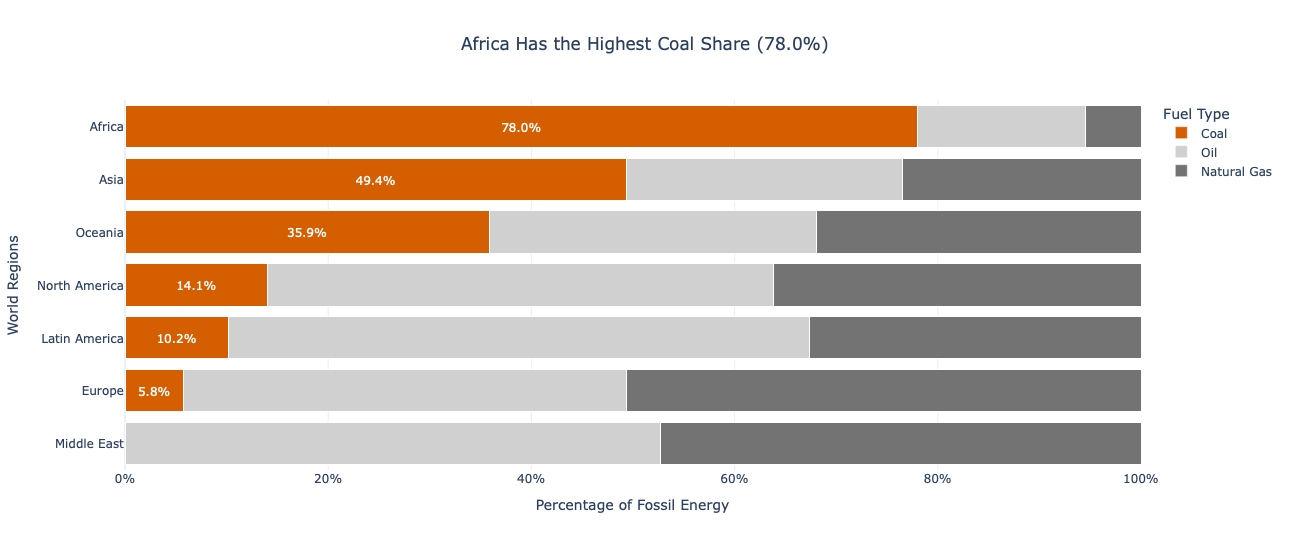

Region with highest coal dependency: Africa
Coal percentage: 78.04 %


In [7]:

# Task 3 — 100% Stacked Bar Chart (Version 2)

# Aggregate fossil fuel consumption by region and source
df_region = (
    df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh']
    .sum()
)

# Calculate total fossil fuel consumption per region
df_region['Region_Total'] = (
    df_region.groupby('Region')['TWh'].transform('sum')
)

# Calculate percentage share of each fuel
df_region['Share_pct'] = (
    df_region['TWh'] / df_region['Region_Total'] * 100
)

# Calculate coal share by region
coal_shares = (
    df_region[df_region['Source'] == 'Coal']
    .set_index('Region')['Share_pct']
)

# Identify the region with the highest coal share
coal_leader = coal_shares.idxmax()
coal_percentage = coal_shares.max()

# Sort regions by coal share
region_order = coal_shares.sort_values().index.tolist()

# Display labels only for Coal
df_region['Coal_Label'] = np.where(
    df_region['Source'] == 'Coal',
    df_region['Share_pct'].map(lambda x: f'{x:.1f}%'),
    ''
)

# New colour palette
source_colors_v2 = {
    'Coal': '#D55E00',
    'Oil': '#D0D0D0',
    'Natural Gas': '#737373'
}

# Create horizontal 100% stacked bar chart
fig4 = px.bar(
    df_region,
    x='Share_pct',
    y='Region',
    color='Source',
    orientation='h',
    barmode='stack',
    text='Coal_Label',
    color_discrete_map=source_colors_v2,
    category_orders={
        'Source': ['Coal', 'Oil', 'Natural Gas'],
        'Region': region_order
    },
    title=(
        f'{coal_leader} Has the Highest Coal Share '
        f'({coal_percentage:.1f}%)'
    ),
    labels={
        'Share_pct': 'Fossil Energy Share (%)',
        'Region': 'Region',
        'Source': 'Energy Source'
    }
)

fig4.update_traces(
    textposition='inside',
    insidetextanchor='middle'
)

fig4.update_layout(
    template='plotly_white',
    title_x=0.5,
    xaxis=dict(
        range=[0, 100],
        ticksuffix='%',
        title='Percentage of Fossil Energy'
    ),
    yaxis=dict(
        autorange='reversed',
        title='World Regions'
    ),
    legend_title='Fuel Type',
    height=550
)

fig4.show()

print("Region with highest coal dependency:", coal_leader)
print("Coal percentage:", round(coal_percentage, 2), "%")


### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

*YOUR ANSWER HERE*
The Task 1 treemap answers which countries and regions contribute the most to total fossil fuel consumption and shows how Coal, Oil and Natural Gas are distributed across the hierarchy.

The Task 3 stacked bar chart answers which region relies most on coal by comparing the percentage of coal in each region's total fossil energy mix.

The treemap is better for understanding hierarchical relationships and absolute energy consumption, whereas the stacked bar chart is better for comparing proportions and identifying coal dependency.